In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [3]:
# Windows에 설치된 맑은 고딕을 사용합니다.
plt.rcParams["font.family"] = "Malgun Gothic"

# 일부 글꼴에서 음수 기호가 깨지는 문제를 피합니다.
plt.rcParams["axes.unicode_minus"] = False

In [4]:
heat = "C:\\AI Equipment Failure Prediction\\data\\17_열처리.csv"  
heat_work = "C:\\AI Equipment Failure Prediction\\data\\17_열처리_공정.csv"  
ht = "C:\\AI Equipment Failure Prediction\\data\\18_열처리.csv"  
wind = "C:\\Users\\rhkdd\\OneDrive\\바탕 화면\\통합프로젝트\\데이터\\경주풍력_SCADA_EDA\\경주풍력_SCADA_UTF8.csv"

In [5]:
df = pd.read_csv(wind)
df.columns.tolist()

['일시',
 '풍력발전기명',
 '풍력발전기 일련번호',
 '강제정지시간(분)',
 '정상가동시간(분)',
 '정상요청정지시간(분)',
 '계획정비시간(분)',
 '기술대기시간(분)',
 '유효전력생산량(kWh)',
 ' 발전기 권선평균온도(섭씨)',
 '전력망 유효전력(kW)',
 '전력망 무효전력(kVAr)',
 '유압시스템 압력(bar)',
 '나셀 내부 공기밀도(단위 부피당 질량)',
 '나셀 방향각(도)',
 '나셀 외기온도(섭씨)',
 '나셀 풍향(도)',
 '나셀 풍속(초속미터)',
 '로터 블레이드 1 위치각(도)',
 '로터 블레이드 2 위치각(도)',
 '로터 블레이드 3 위치각(도)',
 '로터 모터 1 위치각(도)',
 '로터 모터 2 위치각(도)',
 '로터 모터 3 위치각(도)',
 '피치 1 각도(도)',
 '피치 2 각도(도)',
 '피치 3 각도(도)',
 '로터 회전속도(rpm)',
 '타워 내부 케이블 꼬인 누적 각도']

In [6]:
df.describe()

,강제정지시간(분),정상가동시간(분),정상요청정지시간(분),계획정비시간(분),기술대기시간(분),유효전력생산량(kWh),발전기 권선평균온도(섭씨),전력망 유효전력(kW),전력망 무효전력(kVAr),유압시스템 압력(bar),...,로터 블레이드 2 위치각(도),로터 블레이드 3 위치각(도),로터 모터 1 위치각(도),로터 모터 2 위치각(도),로터 모터 3 위치각(도),피치 1 각도(도),피치 2 각도(도),피치 3 각도(도),로터 회전속도(rpm),타워 내부 케이블 꼬인 누적 각도
count,52342.000000,52342.000000,52342.000000,52342.000000,52342.000000,52342.000000,52342.000000,52342.000000,52342.000000,52342.000000,...,52342.000000,52342.000000,52342.000000,52342.000000,52342.000000,52342.000000,52342.000000,52342.000000,52342.000000,52342.000000
mean,0.385548,7.133991,0.309820,0.058743,0.236943,97.382961,53.963936,652.924042,83.316664,124.650058,...,20.215935,19.788348,20.151939,20.122531,19.735944,20.151990,20.122612,19.736005,8.077460,157.006300
std,1.878560,4.440127,1.699715,0.758625,1.187026,119.872164,18.850752,737.522194,46.385811,27.869726,...,35.445083,35.282247,35.556071,35.561471,35.308385,35.556175,35.561616,35.308527,5.107872,237.034774
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-36.142000,0.000000,0.000000,...,-0.059000,-48.760000,-26.398000,0.000000,-48.868000,-26.398000,0.000000,-48.868000,-0.381000,-462.979000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,42.397500,0.000000,80.413250,128.957000,...,0.148000,0.063000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.037000,0.000000
50%,0.000000,10.000000,0.000000,0.000000,0.000000,37.109000,52.226500,337.245000,88.751000,132.106000,...,0.673000,0.220000,0.115000,0.114000,0.103000,0.115000,0.114000,0.103000,9.241000,126.858000
75%,0.000000,10.000000,0.000000,0.000000,0.000000,169.922000,63.981750,1149.162500,110.486000,132.836000,...,11.533500,10.988500,11.451750,11.380500,10.946750,11.451750,11.380500,10.946750,13.099000,364.262000
max,10.000000,10.000000,10.000000,10.000000,10.000000,388.672000,108.706000,2346.400000,214.122000,143.758000,...,308.750000,94.050000,94.500000,308.750000,94.090000,94.500000,308.750000,94.090000,13.571000,688.302000


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 52342 entries, 0 to 52341
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   일시                     52342 non-null  str    
 1   풍력발전기명                 52342 non-null  str    
 2   풍력발전기 일련번호             52342 non-null  str    
 3   강제정지시간(분)              52342 non-null  float64
 4   정상가동시간(분)              52342 non-null  float64
 5   정상요청정지시간(분)            52342 non-null  float64
 6   계획정비시간(분)              52342 non-null  float64
 7   기술대기시간(분)              52342 non-null  float64
 8   유효전력생산량(kWh)           52342 non-null  float64
 9    발전기 권선평균온도(섭씨)        52342 non-null  float64
 10  전력망 유효전력(kW)           52342 non-null  float64
 11  전력망 무효전력(kVAr)         52342 non-null  float64
 12  유압시스템 압력(bar)          52342 non-null  float64
 13  나셀 내부 공기밀도(단위 부피당 질량)  52342 non-null  float64
 14  나셀 방향각(도)              52342 non-null  float64
 15  나셀 외기온도(섭씨)  

In [8]:
df.corr(numeric_only=True).round(1)

,강제정지시간(분),정상가동시간(분),정상요청정지시간(분),계획정비시간(분),기술대기시간(분),유효전력생산량(kWh),발전기 권선평균온도(섭씨),전력망 유효전력(kW),전력망 무효전력(kVAr),유압시스템 압력(bar),...,로터 블레이드 2 위치각(도),로터 블레이드 3 위치각(도),로터 모터 1 위치각(도),로터 모터 2 위치각(도),로터 모터 3 위치각(도),피치 1 각도(도),피치 2 각도(도),피치 3 각도(도),로터 회전속도(rpm),타워 내부 케이블 꼬인 누적 각도
강제정지시간(분),1.0,-0.3,-0.0,-0.0,-0.0,-0.2,-0.2,-0.2,-0.3,-0.0,...,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,-0.3,-0.0
정상가동시간(분),-0.3,1.0,-0.3,-0.1,-0.3,0.4,0.6,0.5,0.7,0.4,...,-0.8,-0.8,-0.8,-0.8,-0.8,-0.8,-0.8,-0.8,0.8,0.1
정상요청정지시간(분),-0.0,-0.3,1.0,-0.0,-0.0,-0.1,-0.2,-0.2,-0.3,-0.4,...,0.4,0.3,0.4,0.4,0.3,0.4,0.4,0.3,-0.3,0.0
계획정비시간(분),-0.0,-0.1,-0.0,1.0,-0.0,-0.1,-0.1,-0.1,-0.1,-0.2,...,0.2,0.2,0.1,0.2,0.2,0.1,0.2,0.2,-0.1,-0.0
기술대기시간(분),-0.0,-0.3,-0.0,-0.0,1.0,-0.2,-0.2,-0.2,-0.0,0.0,...,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.2,-0.3,0.0
유효전력생산량(kWh),-0.2,0.4,-0.1,-0.1,-0.2,1.0,0.8,0.9,0.7,0.2,...,-0.4,-0.4,-0.4,-0.4,-0.4,-0.4,-0.4,-0.4,0.7,0.1
발전기 권선평균온도(섭씨),-0.2,0.6,-0.2,-0.1,-0.2,0.8,1.0,0.9,0.8,0.5,...,-0.5,-0.4,-0.5,-0.5,-0.4,-0.5,-0.5,-0.4,0.8,0.0
전력망 유효전력(kW),-0.2,0.5,-0.2,-0.1,-0.2,0.9,0.9,1.0,0.8,0.2,...,-0.4,-0.4,-0.4,-0.4,-0.4,-0.4,-0.4,-0.4,0.8,-0.0
전력망 무효전력(kVAr),-0.3,0.7,-0.3,-0.1,-0.0,0.7,0.8,0.8,1.0,0.4,...,-0.7,-0.7,-0.7,-0.7,-0.7,-0.7,-0.7,-0.7,0.9,-0.0
유압시스템 압력(bar),-0.0,0.4,-0.4,-0.2,0.0,0.2,0.5,0.2,0.4,1.0,...,-0.2,-0.1,-0.2,-0.2,-0.1,-0.2,-0.2,-0.1,0.4,0.1


In [9]:
corr = df.corr(numeric_only=True)

corr.to_excel('상관계수.xlsx', index=True)

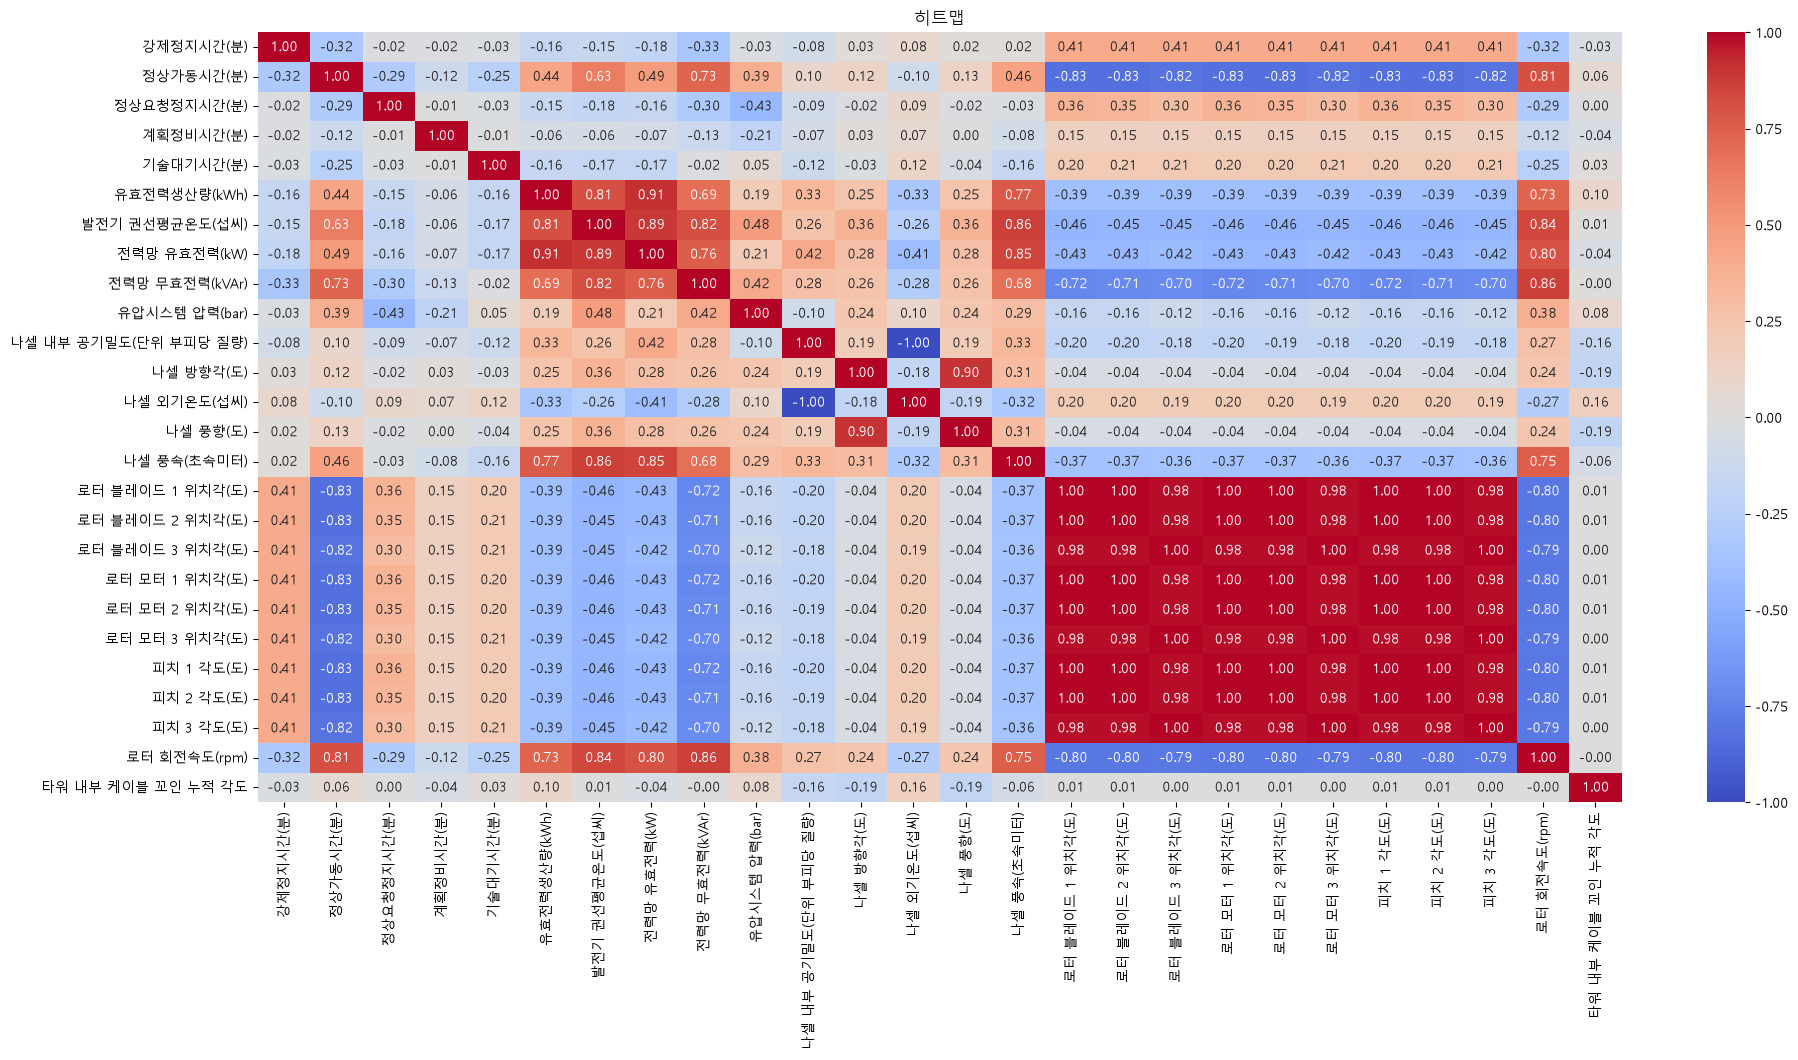

In [10]:
corr=df.corr(numeric_only=True).round(2)
plt.figure(figsize=(22, 10))
sns.heatmap(corr, annot=True,fmt=".2f",cmap="coolwarm")
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
plt.title('히트맵')
plt.show()

In [11]:
df.isna().sum().sum()

np.int64(0)

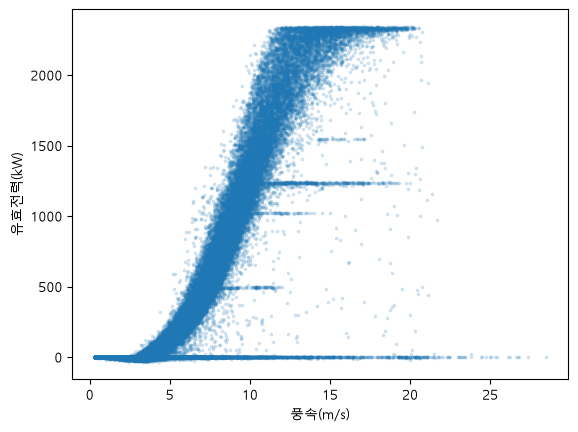

In [12]:
import matplotlib.pyplot as plt

plt.scatter(
    df['나셀 풍속(초속미터)'],
    df['전력망 유효전력(kW)'],
    s=3,
    alpha=0.15
)

plt.xlabel('풍속(m/s)')
plt.ylabel('유효전력(kW)')
plt.show()

In [13]:
#실습4  사용한 데이터 : 경주 풍력 발전기 데이터 분석

ValueError: Could not interpret value `발전기 권선 평균온도(섭씨)` for `y`. An entry with this name does not appear in `data`.

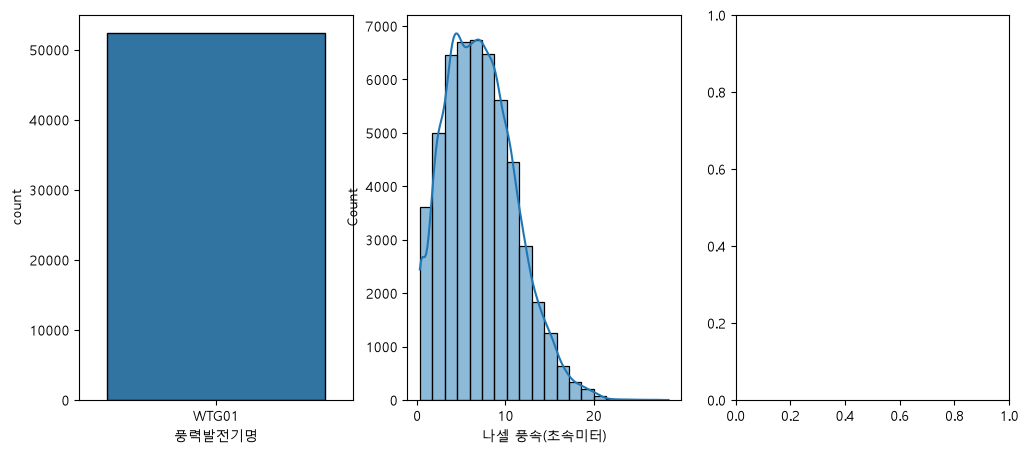

In [20]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12,5))

sns.countplot(data=df, x="풍력발전기명", edgecolor="black", ax=ax1)
sns.histplot(data=df, x="나셀 풍속(초속미터)",edgecolor="black",kde=True,bins=20, ax=ax2)
sns.boxplot(data=df, y="발전기 권선 평균온도(섭씨)", ax=ax3, linewidth=1)

plt.tight_layout()
plt.show()

In [ ]:
#실습5

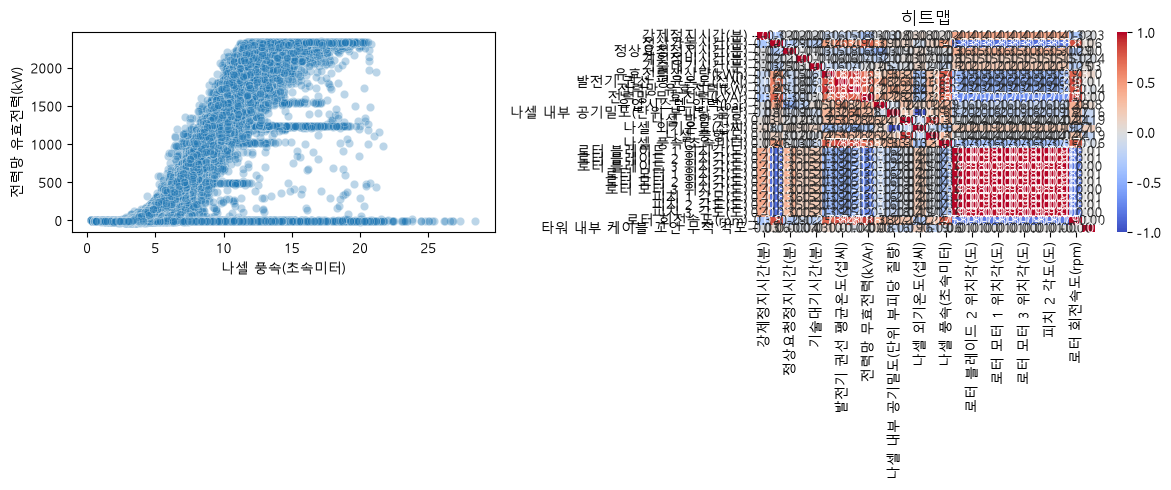

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,5))

sns.scatterplot(data=df, x="나셀 풍속(초속미터)", y='전력망 유효전력(kW)',alpha=0.3, ax=ax1)


corr=df.corr(numeric_only=True).round(2)
sns.heatmap(corr, annot=True,fmt=".2f",cmap="coolwarm", ax=ax2)
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
plt.title('히트맵')


plt.tight_layout()
plt.show()

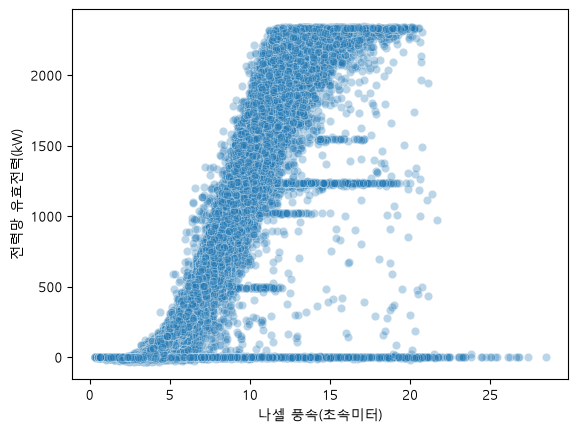

In [ ]:
sns.scatterplot(data=df, x="나셀 풍속(초속미터)", y='전력망 유효전력(kW)',alpha=0.3)
plt.show()

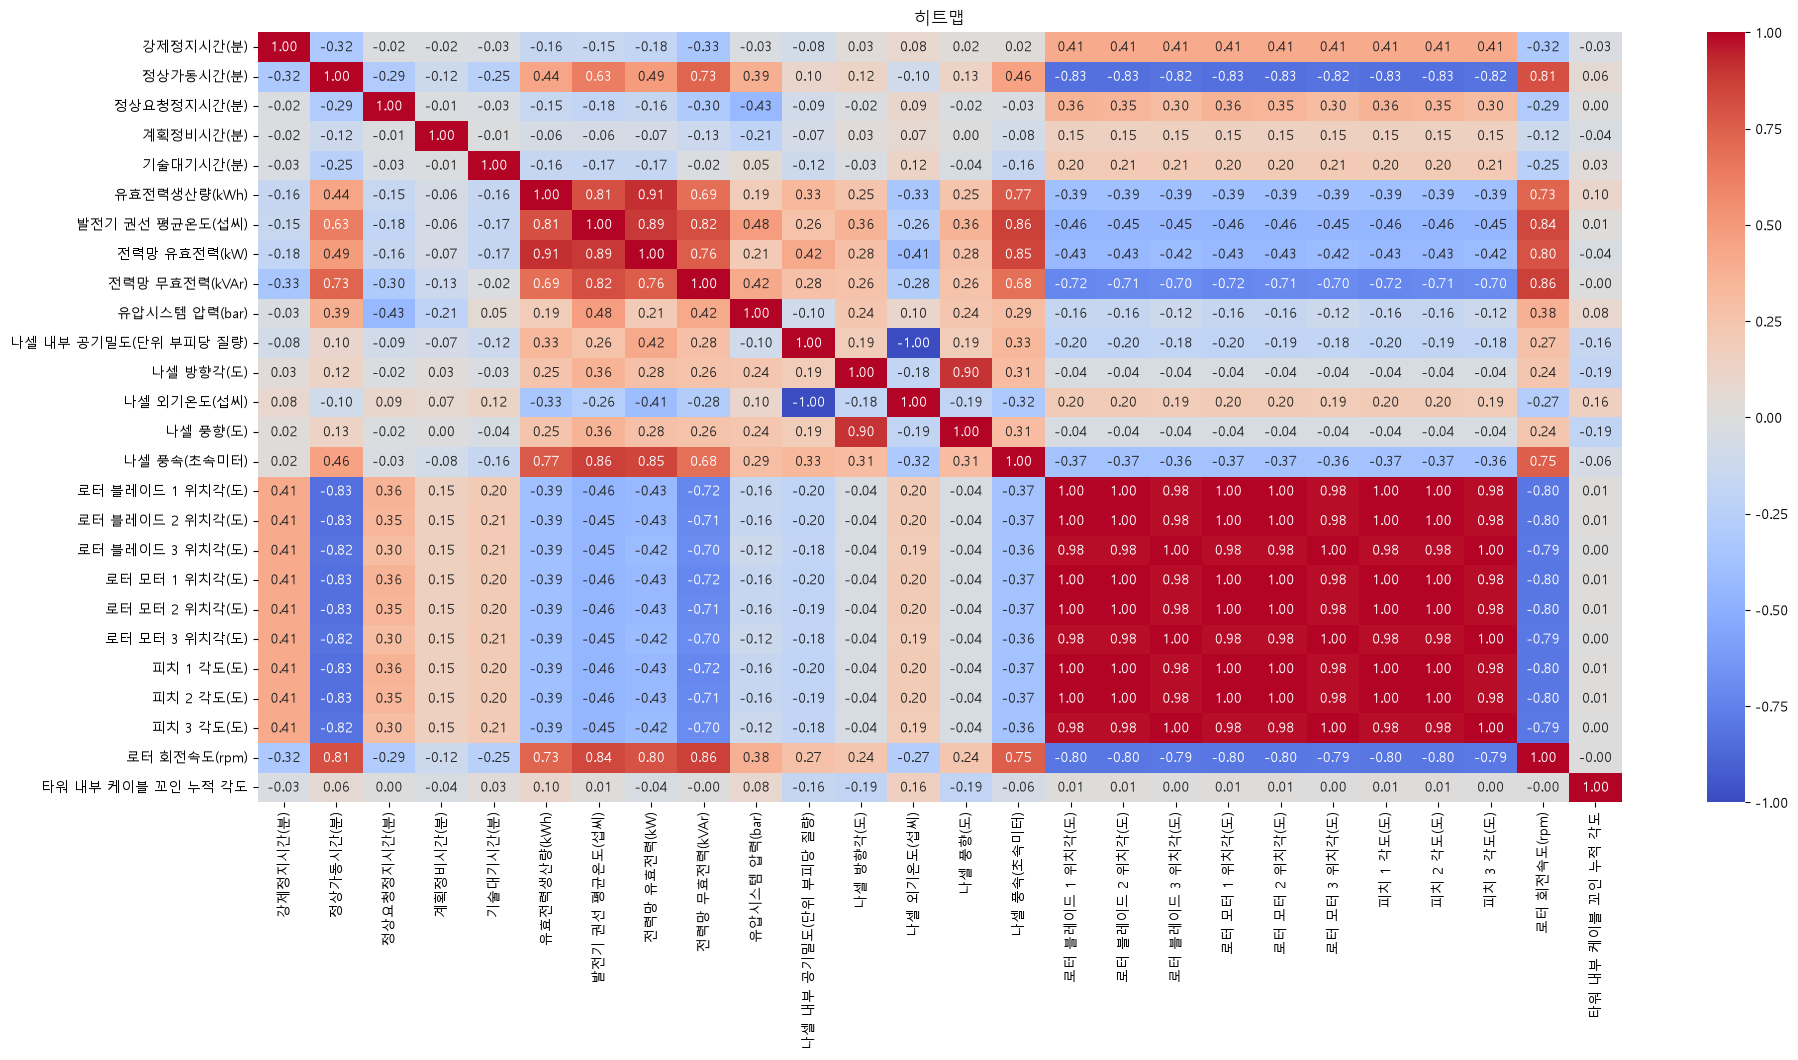

In [ ]:
corr=df.corr(numeric_only=True).round(2)
plt.figure(figsize=(22, 10))
sns.heatmap(corr, annot=True,fmt=".2f",cmap="coolwarm")
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
plt.title('히트맵')
plt.show()

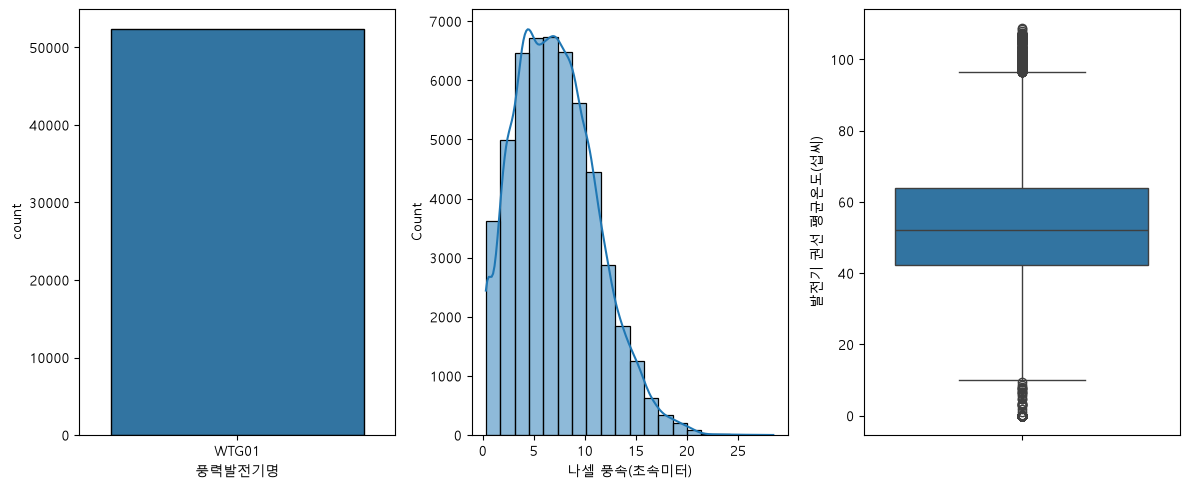

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12,5))

sns.countplot(data=df, x="풍력발전기명", edgecolor="black", ax=ax1)
sns.histplot(data=df, x="나셀 풍속(초속미터)",edgecolor="black",kde=True,bins=20, ax=ax2)
sns.boxplot(data=df, y="발전기 권선 평균온도(섭씨)", ax=ax3, linewidth=1)

plt.tight_layout()
plt.savefig("plot.png")